In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

In [2]:
root = Path.cwd()
df = pd.read_csv(root / "driver_imgs_list.csv")
df.head()

,subject,classname,img
0,p002,c0,img_44733.jpg
1,p002,c0,img_72999.jpg
2,p002,c0,img_25094.jpg
3,p002,c0,img_69092.jpg
4,p002,c0,img_92629.jpg


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22424 entries, 0 to 22423
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   subject    22424 non-null  object
 1   classname  22424 non-null  object
 2   img        22424 non-null  object
dtypes: object(3)
memory usage: 525.7+ KB


In [4]:
df.isna().sum()

subject      0
classname    0
img          0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df["classname"].value_counts().sort_index()

classname
c0    2489
c1    2267
c2    2317
c3    2346
c4    2326
c5    2312
c6    2325
c7    2002
c8    1911
c9    2129
Name: count, dtype: int64

In [7]:
df["subject"].nunique()

26

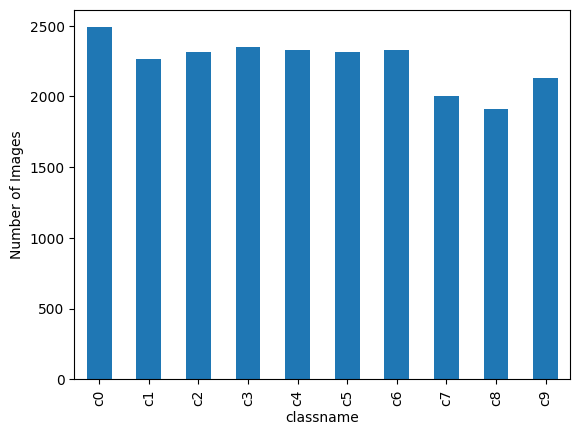

In [8]:
counts = df["classname"].value_counts().sort_index()
counts.plot.bar()
plt.ylabel("Number of Images")
plt.show()

In [9]:
pd.crosstab(df["subject"], df["classname"])

classname,c0,c1,c2,c3,c4,c5,c6,c7,c8,c9
subject,,,,,,,,,,
p002,76,74,86,79,84,76,83,72,44,51
p012,84,95,91,89,97,96,75,72,62,62
p014,100,103,100,100,103,102,101,77,38,52
p015,79,85,88,94,101,101,99,81,86,61
p016,111,102,101,128,104,104,108,101,99,120
p021,135,131,127,128,132,130,126,98,99,131
p022,129,129,128,129,130,130,131,98,98,131
p024,130,129,128,130,129,131,129,101,99,120
p026,130,129,130,131,126,130,128,97,97,98


In [10]:
row = df.iloc[0]
path = root / "imgs" / "train" / row["classname"] / row["img"]

In [11]:
with Image.open(path) as image:
    array = np.array(image.convert("RGB"))

print(array.shape, array.dtype)

(480, 640, 3) uint8


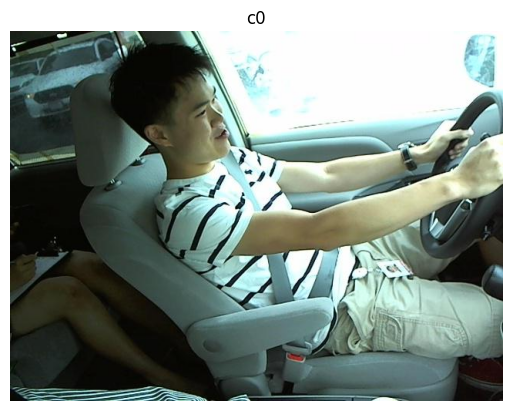

In [12]:
plt.imshow(array)
plt.title(row["classname"])
plt.axis("off")
plt.show()

In [13]:
rng = np.random.default_rng(42)

subjects = df["subject"].unique()
rng.shuffle(subjects)

In [14]:
n_val_subjects = max(1, round(0.2*len(subjects)))
val_subjects = subjects[:n_val_subjects]
is_val = df["subject"].isin(val_subjects)
train_df = df.loc[~is_val].reset_index(drop=True)
val_df = df.loc[is_val].reset_index(drop=True)

In [15]:
assert set(train_df["subject"]).isdisjoint(val_df["subject"])

print(train_df["classname"].value_counts().sort_index())
print(val_df["classname"].value_counts().sort_index())

classname
c0    1926
c1    1810
c2    1825
c3    1856
c4    1842
c5    1816
c6    1820
c7    1589
c8    1509
c9    1645
Name: count, dtype: int64
classname
c0    563
c1    457
c2    492
c3    490
c4    484
c5    496
c6    505
c7    413
c8    402
c9    484
Name: count, dtype: int64


In [16]:
for i in range(len(df)):
    row = df.iloc[i]
    path = root / "imgs" / "train" / row["classname"] / row["img"]
    with Image.open(path) as image:
        image.load()


In [17]:
val_transform = T.Compose([
    T.Resize((192,256)),
    T.ToTensor(),
    T.Normalize(
        mean=(0.5,0.5,0.5),
        std=(0.5,0.5,0.5),
    ),
])

In [18]:
train_transform = T.Compose([
    T.Resize((192, 256)),
    T.RandomRotation(degrees=8),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    T.ToTensor(),
    T.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5),
    ),
])

In [19]:
# Importable module allows Windows DataLoader workers to load this class.
from driver_dataset import DriverDataset


In [20]:
train_dataset = DriverDataset(
    frame=train_df,
    image_root=root / "imgs" / "train",
    transform=train_transform,
)

val_dataset = DriverDataset(
    frame=val_df,
    image_root=root / "imgs" / "train",
    transform=val_transform,
)

In [21]:
image, label = train_dataset[0]

print(image.shape)
print(image.dtype)
print(label)

torch.Size([3, 192, 256])
torch.float32
0


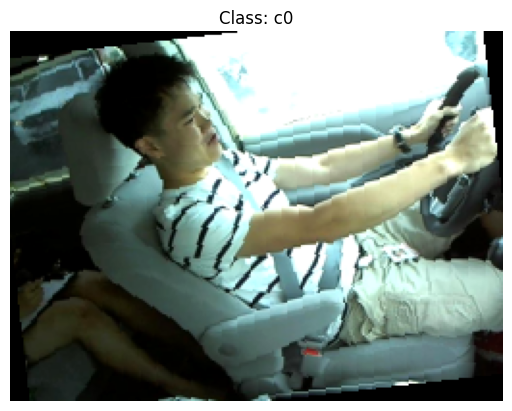

In [22]:
display_image = (image * 0.5 + 0.5).clamp(0, 1)

plt.imshow(display_image.permute(1, 2, 0).numpy())
plt.title(f"Class: c{label}")
plt.axis("off")
plt.show()

In [23]:
# Keep batch size unchanged first so throughput comparisons are meaningful.
BATCH_SIZE = 32
NUM_WORKERS = 4  # Compare 4 and 8 after measuring complete epochs.

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
}
if NUM_WORKERS > 0:
    loader_options.update(persistent_workers=True, prefetch_factor=2)

train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_options)


In [24]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)
print(labels.dtype)

torch.Size([32, 3, 192, 256])
torch.Size([32])
torch.int64


In [25]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )

    def forward(self, x):
        return self.block(x)


class DriverCNN(nn.Module):
    """Three convolution blocks and a small spatial max-pooling head."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 128),
        )
        self.classifier = nn.Sequential(
            # Retain a coarse spatial grid instead of one value per channel.
            nn.AdaptiveMaxPool2d((3, 4)),
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(128 * 3 * 4, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


In [26]:
import random
import time

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Fixed image sizes let cuDNN select efficient convolution algorithms.
torch.backends.cudnn.benchmark = device.type == "cuda"

model = DriverCNN(num_classes=10).to(device)
if device.type == "cuda":
    model = model.to(memory_format=torch.channels_last)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
)

# Mixed precision reduces GPU memory use and can improve speed.
# On CPU, these operations are disabled.
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

print("Device:", device)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

# Verify the architecture without updating BatchNorm statistics.
model.eval()

with torch.no_grad():
    dummy = torch.zeros(2, 3, 192, 256, device=device)
    assert model(dummy).shape == (2, 10)

del dummy

Device: cuda
Trainable parameters: 108,842


In [27]:
def run_epoch(loader, training, collect_confusion=False):
    model.train(training)
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), dtype=torch.int64, device=device)
    count = 0
    # Enable only for a final diagnostic pass to avoid per-batch overhead.
    confusion = (
        torch.zeros(10, 10, dtype=torch.int64, device=device)
        if collect_confusion else None
    )

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(
                device, non_blocking=True,
                memory_format=(torch.channels_last if device.type == "cuda"
                               else torch.contiguous_format),
            )
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            batch_size = labels.size(0)
            predictions = logits.detach().argmax(dim=1)
            loss_sum += loss.detach().float() * batch_size
            correct += (predictions == labels).sum()
            count += batch_size

            if collect_confusion:
                indices = labels * 10 + predictions
                confusion += torch.bincount(indices, minlength=100).reshape(10, 10)

    if count == 0:
        raise ValueError("The loader contains no examples.")
    # Transfer metrics once per epoch rather than synchronizing each batch.
    mean_loss = loss_sum.item() / count
    accuracy = correct.item() / count
    if not np.isfinite(mean_loss):
        raise RuntimeError("Non-finite epoch loss encountered.")

    return {
        "loss": mean_loss,
        "accuracy": accuracy,
        "confusion": confusion.cpu() if collect_confusion else None,
    }


In [28]:
MAX_EPOCHS = 40
EARLY_STOPPING_PATIENCE = 10

checkpoint_path = root / "driver_cnn_maxpool_best.pt"

# Avoid silently overwriting an earlier experiment.
if checkpoint_path.exists():
    raise FileExistsError(
        f"{checkpoint_path.name} already exists. "
        "Choose a new checkpoint filename for this run."
    )

history = []
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

run_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()
    learning_rate = optimizer.param_groups[0]["lr"]

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    scheduler.step(val_metrics["loss"])

    record = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "val_loss": val_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_accuracy": val_metrics["accuracy"],
        "lr": learning_rate,
        "seconds": time.perf_counter() - epoch_start,
    }
    record["images_per_second"] = (
        len(train_dataset) + len(val_dataset)
    ) / record["seconds"]
    history.append(record)

    improved = val_metrics["loss"] < best_val_loss

    if improved:
        best_val_loss = val_metrics["loss"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "architecture": "three_conv_maxpool_3x4",
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "val_loss": best_val_loss,
                "val_accuracy": val_metrics["accuracy"],
                "history": history.copy(),
                "class_to_idx": train_dataset.class_to_idx,
                "train_subjects": sorted(
                    train_df["subject"].unique().tolist()
                ),
                "val_subjects": sorted(
                    val_df["subject"].unique().tolist()
                ),
                "input_size": [192, 256],
                "normalization_mean": [0.5, 0.5, 0.5],
                "normalization_std": [0.5, 0.5, 0.5],
                "seed": SEED,
            },
            checkpoint_path,
        )

    else:
        epochs_without_improvement += 1

    marker = " | saved best" if improved else ""

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"train acc {train_metrics['accuracy']:.2%} | "
        f"val acc {val_metrics['accuracy']:.2%} | "
        f"lr {learning_rate:.2e} | "
        f"{record['seconds']:.1f}s | "
        f"{record['images_per_second']:.1f} images/s"
        f"{marker}",
        flush=True,
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping: validation loss stopped improving.")
        break

elapsed_minutes = (time.perf_counter() - run_start) / 60

print(f"\nTraining time: {elapsed_minutes:.1f} minutes")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Checkpoint: {checkpoint_path}")

Epoch 01/40 | train loss 2.1230 | val loss 1.5112 | train acc 25.90% | val acc 46.59% | lr 1.00e-04 | 64.6s | 347.3 images/s | saved best
Epoch 02/40 | train loss 1.3968 | val loss 1.1048 | train acc 50.35% | val acc 62.75% | lr 1.00e-04 | 51.8s | 432.7 images/s | saved best
Epoch 03/40 | train loss 1.0012 | val loss 0.9852 | train acc 65.51% | val acc 66.28% | lr 1.00e-04 | 51.9s | 432.0 images/s | saved best
Epoch 04/40 | train loss 0.7756 | val loss 0.9008 | train acc 74.12% | val acc 67.13% | lr 1.00e-04 | 52.0s | 431.2 images/s | saved best
Epoch 05/40 | train loss 0.6248 | val loss 0.8909 | train acc 79.84% | val acc 69.08% | lr 1.00e-04 | 52.1s | 430.3 images/s | saved best
Epoch 06/40 | train loss 0.5169 | val loss 0.8682 | train acc 83.58% | val acc 70.18% | lr 1.00e-04 | 51.9s | 432.4 images/s | saved best
Epoch 07/40 | train loss 0.4451 | val loss 0.7721 | train acc 86.14% | val acc 73.15% | lr 1.00e-04 | 51.8s | 432.7 images/s | saved best
Epoch 08/40 | train loss 0.3829 | 